# 01 - Business & Data Understanding

**Proyek:** SuperStore Business Intelligence (Tableau Public)
**Fase- CRISP-DM:** 1. Business Understanding → 2. Data Understanding
**Input:** `data/raw/SuperStore.xlsx`
**Output:** pemahaman bisnis dan data, daftar masalah kualitas data, serta rencana untuk notebook 02 (Data Preparation)

> Notebook ini **tidak mengubah data**. Semua perbaikan dilakukan di notebook 02.and

## Daftar Isi
1. Business Understanding
2. Setup & Load Data
3. Struktur Data 
4. Pemeriksaan Kualitas Data 
5. Cakupan Data 
6. EDA Univariat 
7. EDA Awal untuk Pertanyaan Bisnis
8. Ringkasan Temuan

**Cara Temuan:** jalankan sel dari atas ke bawah secara berurutan (Run All). Beberapa sel memakai variabel dari sel sebelumnya.

## 1. Business Understanding

Sebelum menyentuh data, kita tentukan dulu **untuk siapa** dan **untuk menjawab apa** analisis ini dibuat. Tanpa ini, dashboard hanya jadi kumpulan grafik.

### 1.1 Konteks dan tujuan
SuperStore adalah toko ritel yang menjual furnitur, perlengkapan kantor, dan teknologi ke pelanggan di wilayah Amerika Serikat.
Tujuan proyek: membangun **dashboard BI** yang membantu manajemen memahami performa penjualan dan profitabilitas, serta menemukan area yang perlu diperbaiki.

### 1.2 Persona dan pertanyaan bisnis
**Persona:** Sales Director yang memantau performa bisnis dan memutuskan di mana harus fokus.

| Kode | Pertanyaan bisnis |
|---|---|
| BQ1 | Bagaimana tren Sales, Profit, dan Profit Margin dari 2017 sampai 2020? Apakah ada pola musiman? |
| BQ2 | Kategori, sub-kategori, region, dan state mana yang paling berkontribusi pada profit, dan mana yang merugi? |
| BQ3 | Bagaimana diskon memengaruhi profit? Pada level diskon berapa transaksi mulai merugi? |
| BQ4 | Siapa pelanggan dan segmen yang paling bernilai? Seberapa banyak pelanggan yang membeli ulang? |
| BQ5 | Bagaimana lama pengiriman per Ship Mode dan per region? |

### 1.3 Definisi KPI
KPI didefinisikan di awal supaya angka di Python, SQL, dan Tableau dihitung dengan cara yang sama.

| KPI | Definisi |
|---|---|
| Sales | Jumlah `Sales` |
| Profit | Jumlah `Profit` |
| Profit Margin | `Profit / Sales` |
| Orders | Jumlah `Order_ID` unik |
| Customers | Jumlah `Customer_ID` unik |
| AOV (Average Order Value) | `Sales / Orders` |
| Avg Discount | Rata-rata `Discount` |
| Ship Days | `Ship_Date − Order_Date` (hari) |
| Sales YoY Growth | `(Sales tahun ini − Sales tahun lalu) / Sales tahun lalu` |

### 1.4 Success criteria, scope, dan asumsi
- **Success criteria:** BQ1–BQ5 terjawab; angka KPI konsisten antara Python, SQL (jika dipakai), dan Tableau; dashboard dipublikasikan di Tableau Public; README lengkap di GitHub.
- **Di luar scope:** data return, target/kuota penjualan, biaya pengiriman, dan data pesaing (tidak ada di dataset).
- **Asumsi:** satuan mata uang tidak tercantum di dataset, sehingga diasumsikan USD. Setiap baris adalah satu **order line** (satu produk dalam satu order).

## 2. Setup & Load Data

### 2.1 Import Library

In [1]:
from pathlib import Path        # membuat alamat file yang aman di Windows/Mac/Linux

In [2]:
import numpy as np              # hitungan angka
import pandas as pd             # mengolah tabel (DataFrame)
import matplotlib.pyplot as plt # grafik dasar
import seaborn as sns           # grafik yang lebih rapi

In [3]:
# Pengaturan tampilan: tampilkan semua kolom, angka desimal dengan pemisah ribuan
pd.set_option("display.max_column", 50)
pd.set_option("display.float_format", "{:,.2f}".format)
sns.set_theme(style="whitegrid", context="notebook")

In [4]:
# Cari file data otomatis, baik notebook dijalankan dari folder notebook maupun dari root project
candidates = [
    Path("../data/raw/SuperStore.xlsx"),   # dijalankan dari folder notebook
    Path("data/raw/SuperStore.xlsx"),      # dijalankan dari root project
]
DATA_PATH = next((p for p in candidates if p.exists()), None)

if DATA_PATH is None:
    raise FileNotFoundError("SuperStore.xlsx tidak ditemukan. Cek lokasi file di data/raw/")
print("Memakai file:", DATA_PATH.resolve())

Memakai file: C:\Github\superstore-analysis\data\raw\SuperStore.xlsx


> **Cara membaca hasil:** sel ini tidak menampilkan apapun. Jika muncul `ModuleNotFoundError`, pasang library yang kurang, misalnya `pip install pandas seaborn openpyxl`.

### 2.2 Baca data

In [6]:
# Postal_Code dibaca sebagai teks karena kode pos adalah identitas, bukan angka untuk dijumlahkan
df = pd.read_excel(DATA_PATH, dtype={"Postal_Code": str})

> **Cara membaca hasil:** harus muncul `Baris: 9,994 | Kolom: 20`. Jika jumlahnya beda, berarti file yang dibaca bukan file yang benar.

## 3. Struktur Data

### 3.1 Tipe data dan jumlah nilai terisi

In [7]:
# info(): nama kolom, jumlah nilai terisi (Non-Null Count), dan tipe data (Dtype)
df.info()

<class 'pandas.DataFrame'>
RangeIndex: 9994 entries, 0 to 9993
Data columns (total 20 columns):
 #   Column          Non-Null Count  Dtype         
---  ------          --------------  -----         
 0   Order_ID        9994 non-null   str           
 1   Customer_ID     9994 non-null   str           
 2   Postal_Code     9994 non-null   str           
 3   Product_ID      9994 non-null   str           
 4   Sales           9994 non-null   float64       
 5   Quantity        9994 non-null   int64         
 6   Discount        9994 non-null   float64       
 7   Profit          9994 non-null   float64       
 8   Category        9994 non-null   str           
 9   Sub-Category    9994 non-null   str           
 10  Product_Name    9994 non-null   str           
 11  Order_Date      9994 non-null   datetime64[us]
 12  Ship_Date       9994 non-null   datetime64[us]
 13  Ship_Mode       9994 non-null   str           
 14  Customer_Name   9994 non-null   str           
 15  Segment        

> **Cara membaca hasil:**
> - Semua kolom `9994 non-null` berarti tidak ada sel kosong.
> - `Order_Date` dan `Ship_Date` sudah bertipe tanggal (`datetime64`), jadi bisa dihitung selisihnya.
> - `Sales`, `Discount`, `Profit` bertipe desimal (`float64`), `Quantity` bertipe bilangan bulat (`int64`).
> - Kolom teks bisa tampil sebagai `str` atau `object`, tergantung versi pandas. Keduanya sama untuk teks.

### 3.2 Kamus data

| Kolom | Deskripsi | Peran |
|---|---|---|
| `Order_ID` | ID pesanan (satu order bisa berisi beberapa baris produk) | ID |
| `Customer_ID` | ID pelanggan | ID |
| `Customer_Name` | Nama pelanggan | Dimensi |
| `Segment` | Segmen pelanggan (Consumer, Corporate, Home Office) | Dimensi |
| `Product_ID` | ID produk | ID |
| `Product_Name` | Nama produk | Dimensi |
| `Category` | Kategori produk | Dimensi |
| `Sub-Category` | Sub-kategori produk | Dimensi |
| `Order_Date` | Tanggal pemesanan | Waktu |
| `Ship_Date` | Tanggal pengiriman | Waktu |
| `Ship_Mode` | Mode pengiriman | Dimensi |
| `Country/Region` | Negara | Geografi |
| `Region` | Wilayah (Central, East, South, West) | Geografi |
| `State` | Negara bagian | Geografi |
| `City` | Kota | Geografi |
| `Postal_Code` | Kode pos | Geografi |
| `Sales` | Nilai penjualan baris tersebut | Ukuran (measure) |
| `Quantity` | Jumlah unit | Ukuran (measure) |
| `Discount` | Diskon (0–1) | Ukuran (measure) |
| `Profit` | Profit baris tersebut (negatif berarti rugi) | Ukuran (measure) |

**Istilah penting:** *dimensi* adalah kolom untuk mengelompokkan (kategori, region), *measure* adalah kolom angka untuk dihitung (sales, profit). Di Tableau, pembagian ini dipakai langsung.

## 4. Pemeriksaan Kualitas Data

Tujuan bagian ini: menemukan masalah pada data **sebelum** analisis, lalu mencatatnya sebagai daftar kerja untuk notebook 02.

### 4.1 Missing value

In [8]:
# isna() menandai sel kosong sebagai True; sum() menjumlahkan True per kolom
missing = df.isna().sum()
print(f"Total missing value: {missing.sum()}")

# Tampilkan hanya kolom yang punya nilai kosong
missing[missing > 0]

Total missing value: 0


Series([], dtype: int64)

> **Cara membaca hasil:** `Total missing value: 0` dan tabel kosong berarti tidak ada kolom yang punya nilai kosong.

### 4.2 Duplikat penuh (semua kolom identik)


In [9]:
# duplicated(): True untuk baris yang seluruh kolomnya sama dengan baris sebelumnya
n_full_dup = int(df.duplicated().sum())
print(f"Baris duplikat penuh: {n_full_dup}")

# keep=False menampilkan kedua baris kembar, agar bisa dibandingkan
df[df.duplicated(keep=False)]

Baris duplikat penuh: 1


,Order_ID,Customer_ID,Postal_Code,Product_ID,Sales,Quantity,Discount,Profit,Category,Sub-Category,Product_Name,Order_Date,Ship_Date,Ship_Mode,Customer_Name,Segment,Country/Region,City,State,Region
3405,US-2017-150119,LB-16795,43229,FUR-CH-10002965,281.37,2,0.30,-12.06,Furniture,Chairs,Global Leather Highback Executive Chair with P...,2017-04-23,2017-04-27,Standard Class,Laurel Beltran,Home Office,United States,Columbus,Ohio,East
3406,US-2017-150119,LB-16795,43229,FUR-CH-10002965,281.37,2,0.30,-12.06,Furniture,Chairs,Global Leather Highback Executive Chair with P...,2017-04-23,2017-04-27,Standard Class,Laurel Beltran,Home Office,United States,Columbus,Ohio,East


> **Cara membaca hasil:** ada 1 baris duplikat penuh (order_id US-2017-150119, kursi Global Leather di Columbus). Baris ini akan dihapus di notebook 02.

### 4.3 Granularitas: apakah `Order_ID` + `Product_ID` unik?
Granularitas adalah "salah satu mewakili apa". Di dataset ini seharusnya satu produk dalam satu order, jadi pasangan `Order_ID` + `Product_ID` seharusnya tidak berulang.

In [10]:
grain_cols = ["Order_ID", "Product_ID"]

# Baris extra yang pasangan Order_ID + Product_ID sudah muncul sebelumnya
n_grain_extra = int(df.duplicated(grain_cols).sum())
dup_grain = df[df.duplicated(grain_cols, keep=False)].sort_values(grain_cols)

print(f"Baris extra dengan Order_ID + Product_ID berulang: {n_grain_extra}")
print(f" - di antaranya duplikat penuh: {n_full_dup}")
print(f" - berulang tetapi nilainya berbeda: {n_grain_extra - n_full_dup}")

dup_grain[grain_cols + ["Sales", "Quantity", "Discount", "Profit"]]

Baris extra dengan Order_ID + Product_ID berulang: 8
 - di antaranya duplikat penuh: 1
 - berulang tetapi nilainya berbeda: 7


,Order_ID,Product_ID,Sales,Quantity,Discount,Profit
6498,CA-2018-103135,OFF-BI-10000069,135.09,9,0.00,62.14
6500,CA-2018-103135,OFF-BI-10000069,90.06,6,0.00,41.43
350,CA-2019-129714,OFF-PA-10001970,24.56,2,0.00,11.54
352,CA-2019-129714,OFF-PA-10001970,49.12,4,0.00,23.09
1300,CA-2019-137043,FUR-FU-10003664,572.76,6,0.00,166.10
1301,CA-2019-137043,FUR-FU-10003664,286.38,3,0.00,83.05
9168,CA-2019-140571,OFF-PA-10001954,319.76,14,0.00,147.09
9169,CA-2019-140571,OFF-PA-10001954,45.68,2,0.00,21.01
7881,CA-2020-118017,TEC-AC-10002006,76.75,6,0.20,10.55
7882,CA-2020-118017,TEC-AC-10002006,102.34,8,0.20,14.07


> **Cara membaca hasil:** ada 8 baris extra; 1 duplikat penuh, 7 sisanya **berbeda nilai** (misal Quantity 9 dan 6 untuk produk yang sama dalam satu order). Kemungkinan baris yang sah (dicatat terpisah), jadi **jangan langsung dihapus**. Keputusannya diambil di notebook 02.

### 4.4 Kode pos
`Postal_Code` di file sumber bertipe angka, sehingga kode pos yang diawali `0` kehilangan nol di depannya.

In [11]:
# Panjang tiap kode pos (seharusnya 5 digit)
pc_len = df["Postal_Code"].str.len()
print(pc_len.value_counts().sort_index().to_string())

# Baris dengan kode pos kurang dari 5 digit, dan staten mana aja yang terdampak
short_pc = pc_len < 5
print(f"\nKode pos kurang dari 5 digit: {short_pc.sum()} baris")
print("State terdampak:")
print(df.loc[short_pc, "State"].value_counts().to_string())

Postal_Code
4     449
5    9545

Kode pos kurang dari 5 digit: 449 baris
State terdampak:
State
Massachusetts    135
New Jersey       130
Connecticut       82
Rhode Island      56
New Hampshire     27
Vermont           11
Maine              8


> **Cara membaca hasil:** 449 baris hanya 4 digit, dan semuanya ada di 7 state timur laut (Massachusetts, New Jersey, Connecticut, Rhode Island, New Hampshire, Vermont, Maine). Kode pos di wilayah itu memang diawali `0`, jadi ini bukti nol di depan hilang, bukan data salah. Perbaikannya: tambahkan nol di depan sampai 5 digit.

### 4.5 Konsistensi `Product_ID` dan `Product_Name`

In [12]:
# Berapa Product_ID untuk tiap nama produk, dan berapa nama untuk tiap Product_ID
id_per_name = df.groupby("Product_Name")["Product_ID"].nunique()
name_per_id = df.groupby("Product_ID")["Product_Name"].nunique()

n_name_multi_id = int((id_per_name > 1).sum())
n_id_multi_name = int((name_per_id > 1).sum())
print(f"Product_Name dengan lebih dari 1 Product_ID: {n_name_multi_id}")
print(f"Product_ID dengan lebih dari 1 Product_Name: {n_id_multi_name}")

# Contoh nama produk yang punya beberapa ID
multi = id_per_name[id_per_name > 1].index
(df[df["Product_Name"].isin(multi)]
    [["Product_Name", "Product_ID", "Category", "Sub-Category"]]
    .drop_duplicates()
    .sort_values(["Product_Name", "Product_ID"])
    .head(10))

Product_Name dengan lebih dari 1 Product_ID: 17
Product_ID dengan lebih dari 1 Product_Name: 0


,Product_Name,Product_ID,Category,Sub-Category
985,"#10- 4 1/8"" x 9 1/2"" Recycled Envelopes",OFF-EN-10000461,Office Supplies,Envelopes
1989,"#10- 4 1/8"" x 9 1/2"" Recycled Envelopes",OFF-EN-10000781,Office Supplies,Envelopes
2531,Avery Non-Stick Binders,OFF-BI-10000829,Office Supplies,Binders
336,Avery Non-Stick Binders,OFF-BI-10004140,Office Supplies,Binders
4318,DAX Wood Document Frame,FUR-FU-10000175,Furniture,Furnishings
1459,DAX Wood Document Frame,FUR-FU-10001473,Furniture,Furnishings
34,Easy-staple paper,OFF-PA-10000249,Office Supplies,Paper
1080,Easy-staple paper,OFF-PA-10000349,Office Supplies,Paper
283,Easy-staple paper,OFF-PA-10000474,Office Supplies,Paper
4360,Easy-staple paper,OFF-PA-10000565,Office Supplies,Paper


> **Cara membaca hasil:** 17 nama produk punya lebih dari satu ID, tetapi tidak ada ID yang punya lebih dari satu nama. Artinya `Product_ID` konsisten, jadi gunakan `Product_ID` sebagai kunci produk, bukan `Product_Name`

### 4.6 Logika tanggal

In [13]:
# Lama pengiriman = Ship_Date - Order_Date, dalam hari
ship_days = (df["Ship_Date"] - df["Order_Date"]).dt.days
n_ship_before_order = int((ship_days < 0).sum())

print(f"Ship_Date lebih awal dari Order_Date: {n_ship_before_order}")
print(f"Rentang Order_Date: {df['Order_Date'].min().date()} s.d. {df['Order_Date'].max().date()}")

# Statistik lama pengiriman (.T memutar tabel agar mudah dibaca)
ship_days.describe().to_frame("Ship_Days").T

Ship_Date lebih awal dari Order_Date: 0
Rentang Order_Date: 2017-01-03 s.d. 2020-12-30


,count,mean,std,min,25%,50%,75%,max
Ship_Days,"9,994.00",3.96,1.75,0.00,3.00,4.00,5.00,8.00


> **Cara membaca hasil:** tidak ada baris yang dikirim sebelum dipesan. Data mencakup 3 Jan 2017 sampai 30 Des 2020 (4 tahun penuh), dan lama pengiriman berkisar 0-8 hari dengan rata-rata sekitar 4 hari.

### 4.7 Validasi nilai numerik dan konsistensi kunci

In [14]:
# Nilai yang tidak masuk akal
n_sales_nonpos = int((df["Sales"] <= 0).sum())
n_qty_nonpos = int((df["Quantity"] <= 0).sum())
n_disc_invalid = int((~df["Discount"].between(0, 1)).sum())    # ~ artinya "bukan"
n_loss_rows = int((df["Profit"] < 0).sum())

# Konsistensi kunci: satu ID seharusnya mewakili satu hal saja
n_order_multi_cust = int((df.groupby("Order_ID")["Customer_ID"].nunique() > 1).sum())
n_cust_multi_name = int((df.groupby("Customer_ID")["Customer_Name"].nunique() > 1).sum())
n_state_multi_region = int((df.groupby("State")["Region"].nunique() > 1).sum())

print(f"Sales <= 0                      : {n_sales_nonpos}")
print(f"Quantity <= 0                   : {n_qty_nonpos}")
print(f"Discount di luar 0-1            : {n_disc_invalid}")
print(f"Baris dengan Profit negatif     : {n_loss_rows:,} ({n_loss_rows / len(df):.1%})")
print(f"Order dengan >1 Customer_ID     : {n_order_multi_cust}")
print(f"Customer_ID dengan >1 nama      : {n_cust_multi_name}")
print(f"State yang ada di >1 Region     : {n_state_multi_region}")
print(f"Nilai unik Country/Region       : {df['Country/Region'].unique().tolist()}")


Sales <= 0                      : 0
Quantity <= 0                   : 0
Discount di luar 0-1            : 0
Baris dengan Profit negatif     : 1,871 (18.7%)
Order dengan >1 Customer_ID     : 0
Customer_ID dengan >1 nama      : 0
State yang ada di >1 Region     : 0
Nilai unik Country/Region       : ['United States']


> **Cara membaca hasil:** semua pemeriksaan bernilai 0, kecuali profit negatif: 1.871 baris (18,7%). Profit negatif **bukan error**, itu transaksi yang benar-benar rugi dan justru menarik untuk dianalisis. Country/Region hanya satu nilai (United States), jadi kolom ini tidak berguna untuk analisis dan bisa dibuang di notebook 02.

### 4.8 Ringkasan kualitas data

In [15]:
def status(n):
    return "OK" if n == 0 else "Perlu tindakan"

quality = pd.DataFrame(
    [
        ["Missing value", int(missing.sum()), status(int(missing.sum())), "-"],
        ["Duplikat penuh", n_full_dup, status(n_full_dup), "Hapus duplikat"],
        ["Order_ID + Product_ID berulang (nilai berbeda)", n_grain_extra - n_full_dup,
         status(n_grain_extra - n_full_dup), "Tinjau; kemungkinan baris sah, putuskan di notebook 02"],
        ["Kode pos < 5 digit", int(short_pc.sum()), status(int(short_pc.sum())), "Tambahkan nol di depan (zfill 5)"],
        ["Product_Name dengan >1 Product_ID", n_name_multi_id, status(n_name_multi_id), "Tinjau; pakai Product_ID sebagai kunci"],
        ["Product_ID dengan >1 Product_Name", n_id_multi_name, status(n_id_multi_name), "-"],
        ["Ship_Date < Order_Date", n_ship_before_order, status(n_ship_before_order), "-"],
        ["Sales atau Quantity <= 0", n_sales_nonpos + n_qty_nonpos, status(n_sales_nonpos + n_qty_nonpos), "-"],
        ["Discount di luar 0-1", n_disc_invalid, status(n_disc_invalid), "-"],
        ["Customer_ID dengan >1 nama", n_cust_multi_name, status(n_cust_multi_name), "-"],
        ["State di >1 Region", n_state_multi_region, status(n_state_multi_region), "-"],
    ],
    columns=["Pemeriksaan", "Jumlah", "Status", "Rencana di notebook 02"],
)
quality

,Pemeriksaan,Jumlah,Status,Rencana di notebook 02
0,Missing value,0,OK,-
1,Duplikat penuh,1,Perlu tindakan,Hapus duplikat
2,Order_ID + Product_ID berulang (nilai berbeda),7,Perlu tindakan,"Tinjau; kemungkinan baris sah, putuskan di not..."
3,Kode pos < 5 digit,449,Perlu tindakan,Tambahkan nol di depan (zfill 5)
4,Product_Name dengan >1 Product_ID,17,Perlu tindakan,Tinjau; pakai Product_ID sebagai kunci
5,Product_ID dengan >1 Product_Name,0,OK,-
6,Ship_Date < Order_Date,0,OK,-
7,Sales atau Quantity <= 0,0,OK,-
8,Discount di luar 0-1,0,OK,-
9,Customer_ID dengan >1 nama,0,OK,-


> **Cara membaca hasil:** tabel ini merangkum variabel dari 4.1-4.7, jadi sel-sel sebelumnya harus sudah dijalankan. Baris berstatus *Perlu tindakan* menjadi daftar kerja di notebook 02.

## 5. Cakupan Data

Angka besar yang menggambarkan ukuran dataset. Angka-angka ini juga dipakai sebagai **angka acuan** untuk mencocokkan hasil di SQL dan Tableau nanti.

In [16]:
coverage = pd.Series(
    {
        "Baris (order line)": len(df),
        "Order unik": df["Order_ID"].nunique(),
        "Pelanggan unik": df["Customer_ID"].nunique(),
        "Product_ID unik": df["Product_ID"].nunique(),
        "Product_Name unik": df["Product_Name"].nunique(),
        "State": df["State"].nunique(),
        "City": df["City"].nunique(),
        "Total Sales": df["Sales"].sum(),
        "Total Profit": df["Profit"].sum(),
        "Profit Margin (%)": df["Profit"].sum() / df["Sales"].sum() * 100,
    }
)
coverage.to_frame("Nilai")

,Nilai
Baris (order line),"9,994.00"
Order unik,"5,009.00"
Pelanggan unik,793.00
Product_ID unik,"1,862.00"
Product_Name unik,"1,817.00"
State,49.00
City,531.00
Total Sales,"2,297,200.86"
Total Profit,"286,397.02"
Profit Margin (%),12.47


> **Cara membaca hasil:** 9.994 baris berasal dari 5.009 order dan 793 pelanggan. Total Sales sekitar 2,30 juta, Profit sekitar 286 ribu, jadi Profit Margin sekitar 12,5%. Catat angka penting: nanti total di Tableau harus sama persis (sebelum cleaning).

## 6. EDA Univariat

*Univariat* artinya melihat **satu variabel dalam satu bulan:** sebarannya, nilai tipikalnya, dan nilai ekstremnya.

### 6.1 Variabel numerik

In [17]:
num_cols = ["Sales", "Quantity", "Discount", "Profit"]

# describe(): rata-rata, standar deviasi, min, kuartil, max
df[num_cols].describe().T

,count,mean,std,min,25%,50%,75%,max
Sales,"9,994.00",229.86,623.25,0.44,17.28,54.49,209.94,"22,638.48"
Quantity,"9,994.00",3.79,2.23,1.00,2.00,3.00,5.00,14.00
Discount,"9,994.00",0.16,0.21,0.00,0.00,0.20,0.20,0.80
Profit,"9,994.00",28.66,234.26,"-6,599.98",1.73,8.67,29.36,"8,399.98"


> **Cara membaca hasil:**
> - `Sales`: median 54 jauh di bawah rata-rata 230, artinya banyak transaksi kecil dan sedikit transaksi sangat besar (maks 22.638).
> - `Profit`: berkisar dari sekitar −6.600 sampai +8.400, jadi ada transaksi dengan kerugian dan keuntungan ekstrem.
> - `Discount`: maksimum 0,80 (80%).

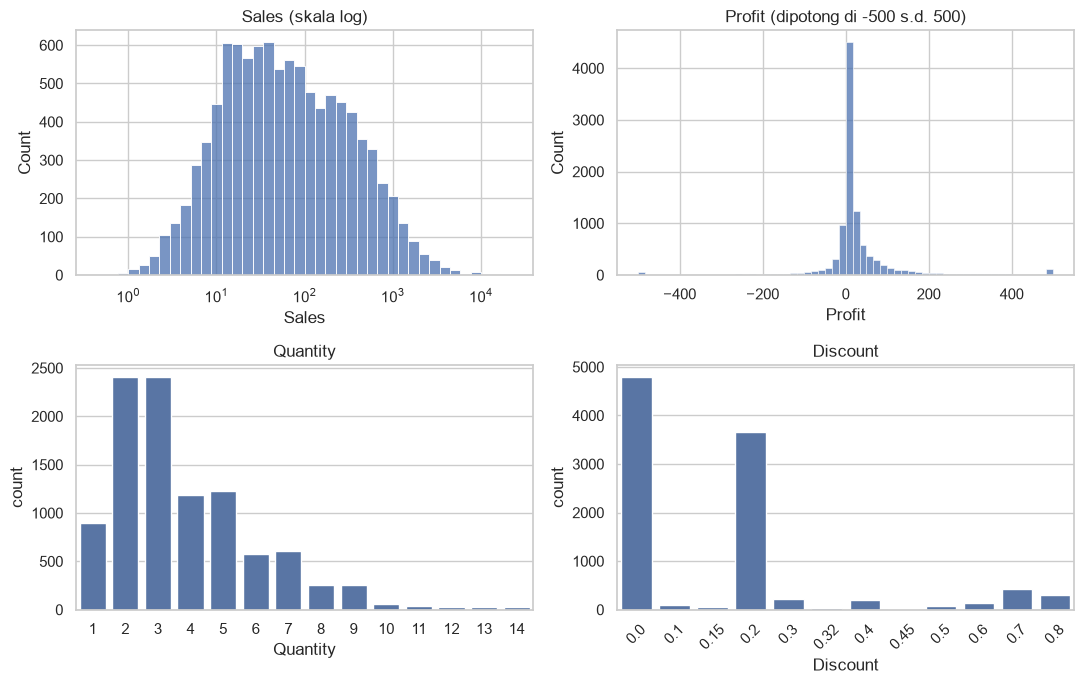

In [18]:
fig, axes = plt.subplots(2, 2, figsize=(11, 7))

# Sales sangat miring ke kanan, jadi dipakai skala logaritmik
sns.histplot(df["Sales"], log_scale=True, bins=40, ax=axes[0, 0])
axes[0, 0].set_title("Sales (skala log)")

# Profit dipotong agar grafik tidak tertarik oleh nilai ekstrem
sns.histplot(df["Profit"].clip(-500, 500), bins=60, ax=axes[0, 1])
axes[0, 1].set_title("Profit (dipotong di -500 s.d. 500)")

sns.countplot(x=df["Quantity"], ax=axes[1, 0], color="#4c72b0")
axes[1, 0].set_title("Quantity")

sns.countplot(x=df["Discount"], ax=axes[1, 1], color="#4c72b0")
axes[1, 1].set_title("Discount")
axes[1, 1].tick_params(axis="x", rotation=45)

plt.tight_layout()
plt.show()

> **Cara membaca hasil:** mayoritas transaksi bernilai kecil dengan profit di sekitar nol. Diskon paling sering 0% dan 20%, sedangkan diskon besar (30% ke atas) jarang tetapi ada.

### 6.2 Variabel kategorikal

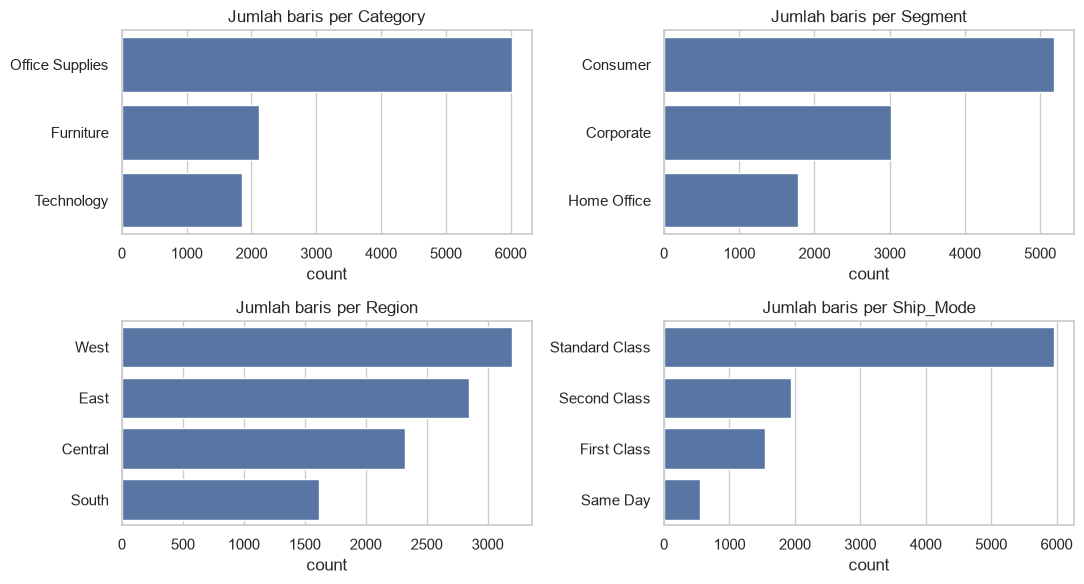

In [19]:
cat_cols = ["Category", "Segment", "Region", "Ship_Mode"]

fig, axes = plt.subplots(2, 2, figsize=(11, 6))
for ax, col in zip(axes.ravel(), cat_cols):
    order = df[col].value_counts().index          # urutkan dari yang terbanyak
    sns.countplot(data=df, y=col, order=order, ax=ax, color="#4c72b0")
    ax.set_title(f"Jumlah baris per {col}")
    ax.set_ylabel("")

plt.tight_layout()
plt.show()

> **Cara membaca hasil:** Office Supplies adalah kategori dengan baris terbanyak, Consumer adalah segmen terbesar, dan mayoritas pengiriman memakai Standard Class.

## 7. EDA Awal untuk Pertanyaan Bisnis

Bagian ini memberi **gambaran awal** untuk BQ1–BQ5. Analisis yang lebih dalam (segmentasi pelanggan, driver profit) dilakukan di notebook 03.

### 7.1 Fungsi bantu: tabel KPI
Fungsi ini dipakai berulang supaya KPI selalu dihitung dengan cara yang sama.

In [20]:
def kpi_table(data, by):
    """Ringkasan KPI per dimensi (kolom `by`)."""
    t = data.groupby(by).agg(
        Sales=("Sales", "sum"),
        Profit=("Profit", "sum"),
        Orders=("Order_ID", "nunique"),     # nunique = hitung nilai unik
        Avg_Discount=("Discount", "mean"),
    )
    t["Margin_%"] = t["Profit"] / t["Sales"] * 100
    return t

> **Cara membaca hasil:** sel ini hanya mendefinisikan fungsi, jadi tidak ada output.

### 7.2 Kategori dan sub-kategori (BQ2)

In [21]:
kpi_table(df, "Category").sort_values("Profit", ascending=False)

,Sales,Profit,Orders,Avg_Discount,Margin_%
Category,,,,,
Technology,"836,154.03","145,454.95",1544,0.13,17.40
Office Supplies,"719,047.03","122,490.80",3742,0.16,17.04
Furniture,"741,999.80","18,451.27",1764,0.17,2.49


> **Cara membaca hasil:** Furniture punya Sales yang hampir sama dengan Office Supplies, tetapi marginnya hanya sekitar 2,5% dibanding 17% (Office Supplies) dan 17,4% (Technology). Ini sinyal pertama bahwa ada masalah profitabilitas di Furniture.

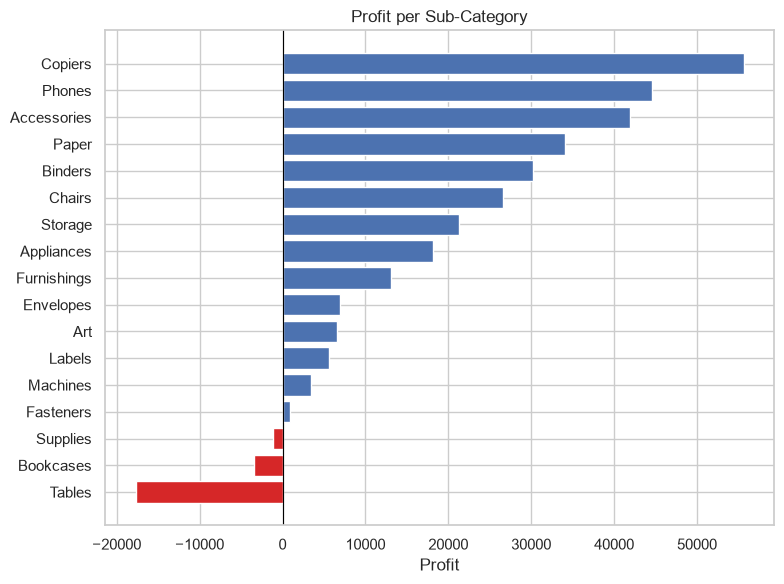

,Sales,Profit,Orders,Avg_Discount,Margin_%
Sub-Category,,,,,
Tables,"206,965.53","-17,725.48",307,0.26,-8.56
Bookcases,"114,880.00","-3,472.56",224,0.21,-3.02
Supplies,"46,673.54","-1,189.10",187,0.08,-2.55
Fasteners,"3,024.28",949.52,215,0.08,31.40
Machines,"189,238.63","3,384.76",112,0.31,1.79
Labels,"12,486.31","5,546.25",346,0.07,44.42
Art,"27,118.79","6,527.79",731,0.07,24.07
Envelopes,"16,476.40","6,964.18",249,0.08,42.27
Furnishings,"91,705.16","13,059.14",877,0.14,14.24


In [22]:
sub_tbl = kpi_table(df, "Sub-Category").sort_values("Profit")

fig, ax = plt.subplots(figsize=(8, 6))
colors = np.where(sub_tbl["Profit"] < 0, "#d62728", "#4c72b0")   # merah jika rugi
ax.barh(sub_tbl.index, sub_tbl["Profit"], color=colors)
ax.axvline(0, color="black", linewidth=0.8)
ax.set_title("Profit per Sub-Category")
ax.set_xlabel("Profit")
plt.tight_layout()
plt.show()

sub_tbl

> **Cara membaca hasil:** tiga sub-kategori merugi: **Tables (sekitar −17,7 ribu)**, **Bookcases (sekitar −3,5 ribu)**, dan **Supplies (sekitar −1,2 ribu)**. Tables dan Bookcases termasuk Furniture, itulah penyebab margin Furniture rendah. Perhatikan juga rata-rata diskon Tables cukup tinggi (sekitar 26%), jauh di atas Paper atau Labels (sekitar 7%).

### 7.3 Region dan state (BQ2)

In [23]:
kpi_table(df, "Region").sort_values("Profit", ascending=False)

,Sales,Profit,Orders,Avg_Discount,Margin_%
Region,,,,,
West,"725,457.82","108,418.45",1611,0.11,14.94
East,"678,781.24","91,522.78",1401,0.15,13.48
South,"391,721.91","46,749.43",822,0.15,11.93
Central,"501,239.89","39,706.36",1175,0.24,7.92


> **Cara membaca hasil:** West punya margin tertinggi (sekitar 14,9%), sedangkan Central terendah (sekitar 7,9%) dengan rata-rata diskon tertinggi (sekitar 24%).

In [24]:
state_tbl = kpi_table(df, "State").sort_values("Profit")
print(f"Jumlah state dengan profit negatif: {(state_tbl['Profit'] < 0).sum()}")

show_cols = ["Sales", "Profit", "Margin_%"]
print("\n5 state dengan profit terendah:")
print(state_tbl[show_cols].head(5).to_string())

print("\n5 state dengan profit tertinggi:")
print(state_tbl[show_cols].tail(5).iloc[::-1].to_string())

Jumlah state dengan profit negatif: 10

5 state dengan profit terendah:
                    Sales     Profit  Margin_%
State                                         
Texas          170,188.05 -25,729.36    -15.12
Ohio            78,258.14 -16,971.38    -21.69
Pennsylvania   116,511.91 -15,559.96    -13.35
Illinois        80,166.10 -12,607.89    -15.73
North Carolina  55,603.16  -7,490.91    -13.47

5 state dengan profit tertinggi:
                Sales    Profit  Margin_%
State                                    
California 457,687.63 76,381.39     16.69
New York   310,876.27 74,038.55     23.82
Washington 138,641.27 33,402.65     24.09
Michigan    76,269.61 24,463.19     32.07
Virginia    70,636.72 18,597.95     26.33


> **Cara membaca hasil:** 10 dari 49 state merugi. Yang terbesar: Texas, Ohio, Pennsylvania, dan Illinois. Menariknya Texas punya Sales besar (sekitar 170 ribu) tetapi tetap rugi, jadi masalahnya bukan volume.

### 7.4 Tren waktu (BQ1)

In [25]:
# Tambahkan kolom Year dan Month (hanya untuk analisis ini; df asli tidak berubah)
df_t = df.assign(Year=df["Order_Date"].dt.year, Month=df["Order_Date"].dt.month)

year_tbl = kpi_table(df_t, "Year")
year_tbl["Sales_YoY_%"] = year_tbl["Sales"].pct_change() * 100   # pertumbuhan dibanding tahun sebelumnya
year_tbl

,Sales,Profit,Orders,Avg_Discount,Margin_%,Sales_YoY_%
Year,,,,,,
2017,"484,247.50","49,543.97",969,0.16,10.23,NaN
2018,"470,532.51","61,618.60",1038,0.16,13.10,-2.83
2019,"609,205.60","81,795.17",1315,0.15,13.43,29.47
2020,"733,215.26","93,439.27",1687,0.16,12.74,20.36


> **Cara membaca hasil:** Sales turun sekitar 2,8% di 2018, lalu naik sekitar 29,5% di 2019 dan 20,4% di 2020. Margin membaik dari sekitar 10% (2017) ke 13% (2018–2019), lalu sedikit turun di 2020.

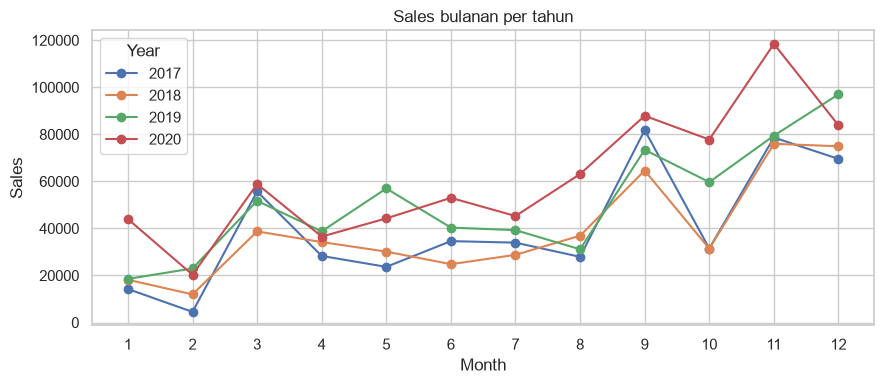

Kontribusi Sales per bulan (%):
Month
1     4.10
2     2.60
3     8.90
4     6.00
5     6.70
6     6.60
7     6.40
8     6.90
9    13.40
10    8.70
11   15.30
12   14.20


In [26]:
# Sales per bulan, satu garis per tahun
monthly = df_t.groupby(["Year", "Month"])["Sales"].sum().unstack("Year")

ax = monthly.plot(marker="o", figsize=(9, 4))
ax.set_xticks(range(1, 13))
ax.set_title("Sales bulanan per tahun")
ax.set_ylabel("Sales")
plt.tight_layout()
plt.show()

# Kontribusi tiap bulan terhadap total Sales (%)
month_share = (df_t.groupby("Month")["Sales"].sum() / df["Sales"].sum() * 100).round(1)
print("Kontribusi Sales per bulan (%):")
print(month_share.to_string())

> **Cara membaca hasil:** pola musiman jelas. September (13,4%), November (15,3%), dan Desember (14,2%) bersama-sama menyumbang sekitar 43% dari seluruh Sales. Ketiga bulan ini selalu menjadi tiga bulan tertinggi di keempat tahun (porsinya 40–48% per tahun), sedangkan Januari dan Februari umumnya paling rendah.

### 7.5 Diskon vs profit (BQ3)

In [27]:
# Untuk tiap level diskon: jumlah baris, total sales, total profit, rata-rata profit per baris
disc_tbl = df.groupby("Discount").agg(
    Rows=("Profit", "size"),
    Sales=("Sales", "sum"),
    Total_Profit=("Profit", "sum"),
    Avg_Profit=("Profit", "mean"),
)
disc_tbl

,Rows,Sales,Total_Profit,Avg_Profit
Discount,,,,
0.00,4798,"1,087,908.47","320,987.60",66.90
0.10,94,"54,369.35","9,029.18",96.06
0.15,52,"27,558.52","1,418.99",27.29
0.20,3657,"764,594.37","90,337.31",24.70
0.30,227,"103,226.65","-10,369.28",-45.68
0.32,27,"14,493.46","-2,391.14",-88.56
0.40,206,"116,417.78","-23,057.05",-111.93
0.45,11,"5,484.97","-2,493.11",-226.65
0.50,66,"58,918.54","-20,506.43",-310.70


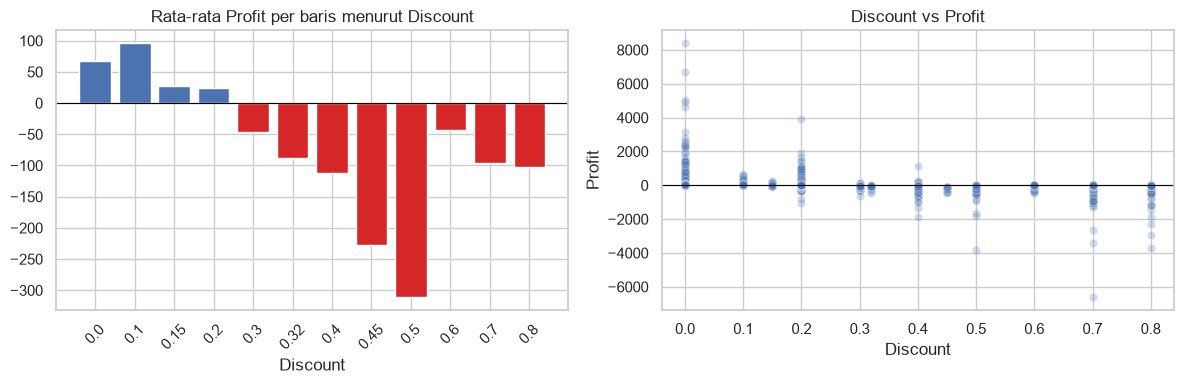

Baris dengan Discount >= 30%: 1,393
Total Profit dari baris tersebut: -135,376


In [28]:
fig, axes = plt.subplots(1, 2, figsize=(12, 4))

# Kiri: rata-rata profit per baris, merah jika negatif
colors = np.where(disc_tbl["Avg_Profit"] < 0, "#d62728", "#4c72b0")
axes[0].bar(disc_tbl.index.astype(str), disc_tbl["Avg_Profit"], color=colors)
axes[0].axhline(0, color="black", linewidth=0.8)
axes[0].set_title("Rata-rata Profit per baris menurut Discount")
axes[0].set_xlabel("Discount")
axes[0].tick_params(axis="x", rotation=45)

# Kanan: setiap titik adalah satu baris transaksi
sns.scatterplot(data=df, x="Discount", y="Profit", alpha=0.25, ax=axes[1])
axes[1].axhline(0, color="black", linewidth=0.8)
axes[1].set_title("Discount vs Profit")

plt.tight_layout()
plt.show()

high_disc = df[df["Discount"] >= 0.3]
print(f"Baris dengan Discount >= 30%: {len(high_disc):,}")
print(f"Total Profit dari baris tersebut: {high_disc['Profit'].sum():,.0f}")

> **Cara membaca hasil:** tanpa diskon dan dengan diskon 10–20%, rata-rata profit per baris positif. Begitu diskon mencapai **30% ke atas**, rata-rata profit selalu negatif. Total 1.393 baris dengan diskon 30%+ menghasilkan profit sekitar **−135 ribu**, sekitar 87% dari total kerugian transaksi di dataset (sekitar −156 ribu).
>
> **Catatan penting:** ini baru **korelasi**. Produk tertentu (misalnya Tables) mungkin lebih sering didiskon, sehingga efek diskon bisa tercampur dengan efek produk. Hal ini dicek lebih lanjut di notebook 03.

### 7.6 Segmen dan pelanggan (BQ4)

In [29]:
kpi_table(df, "Segment").sort_values("Sales", ascending=False)

,Sales,Profit,Orders,Avg_Discount,Margin_%
Segment,,,,,
Consumer,"1,161,401.34","134,119.21",2586,0.16,11.55
Corporate,"706,146.37","91,979.13",1514,0.16,13.03
Home Office,"429,653.15","60,298.68",909,0.15,14.03


> **Cara membaca hasil:** Consumer adalah segmen terbesar dalam Sales, tetapi Home Office punya margin tertinggi (sekitar 14%) dan Consumer terendah (sekitar 11,5%). Perbedaannya tidak besar.

In [30]:
# Ringkasan per pelanggan
cust = df.groupby("Customer_ID").agg(
    Orders=("Order_ID", "nunique"),
    Sales=("Sales", "sum"),
    Profit=("Profit", "sum"),
)

repeat_rate = (cust["Orders"] > 1).mean()            # proporsi pelanggan dengan >1 order
n_top = int(len(cust) * 0.2)                         # jumlah pelanggan di 20% teratas
top20_share = cust["Sales"].nlargest(n_top).sum() / cust["Sales"].sum()

print(f"Pelanggan dengan lebih dari 1 order: {repeat_rate:.1%}")
print(f"Median jumlah order per pelanggan: {cust['Orders'].median():.0f}")
print(f"Kontribusi Sales dari 20% pelanggan teratas: {top20_share:.1%}")

# 10 pelanggan dengan Sales terbesar
cust.nlargest(10, "Sales")

Pelanggan dengan lebih dari 1 order: 98.5%
Median jumlah order per pelanggan: 6
Kontribusi Sales dari 20% pelanggan teratas: 48.0%


,Orders,Sales,Profit
Customer_ID,,,
SM-20320,5,"25,043.05","-1,980.74"
TC-20980,5,"19,052.22","8,981.32"
RB-19360,6,"15,117.34","6,976.10"
TA-21385,4,"14,595.62","4,703.79"
AB-10105,10,"14,473.57","5,444.81"
KL-16645,12,"14,175.23",806.86
SC-20095,9,"14,142.33","5,757.41"
HL-15040,6,"12,873.30","5,622.43"
SE-20110,11,"12,209.44","2,650.68"


> **Cara membaca hasil:** sekitar 98,5% pelanggan membeli lebih dari sekali (median 6 order), jadi basis pelanggannya sangat loyal. 20% pelanggan teratas menyumbang sekitar 48% Sales. Perhatikan juga pelanggan `SM-20320`: Sales terbesar (sekitar 25 ribu) tetapi profitnya negatif. Pelanggan besar belum tentu menguntungkan.

### 7.7 Pengiriman (BQ5)

In [31]:
# Lama pengiriman per Ship Mode
(df.assign(Ship_Days=ship_days)
   .groupby("Ship_Mode")["Ship_Days"]
   .agg(["count", "mean", "min", "max"])
   .sort_values("mean"))

,count,mean,min,max
Ship_Mode,,,,
Same Day,543,0.04,0,1
First Class,1538,2.18,1,4
Second Class,1945,3.24,1,5
Standard Class,5968,5.01,3,8


In [32]:
# Rata-rata lama pengiriman per Region
(df.assign(Ship_Days=ship_days)
   .groupby("Region")["Ship_Days"]
   .mean()
   .sort_values()
   .to_frame("Avg_Ship_Days"))

,Avg_Ship_Days
Region,
East,3.91
West,3.93
South,3.96
Central,4.06


> **Cara membaca hasil:** Ship Mode sangat menentukan lama pengiriman: Same Day sekitar 0,04 hari, First Class 2,2 hari, Second Class 3,2 hari, Standard Class 5,0 hari. Antar-region perbedaannya kecil (sekitar 3,9 sampai 4,1 hari), jadi region bukan faktor utama.

## 8. Ringkasan Temuan

### 8.1 Gambaran umum
- 9.994 baris (order line), 5.009 order, 793 pelanggan, 1.862 Product_ID, periode **3 Jan 2017 – 30 Des 2020**.
- Total Sales sekitar 2,30 juta, Profit sekitar 286 ribu, Profit Margin sekitar 12,5%.

### 8.2 Kualitas data
Secara umum bersih (tidak ada missing value dan logika tanggal valid). Masalah yang perlu ditangani di notebook 02:
1. **1 baris duplikat penuh**.
2. **7 baris tambahan** dengan `Order_ID` + `Product_ID` berulang tetapi nilainya berbeda (perlu ditinjau, kemungkinan baris yang sah).
3. **449 kode pos hanya 4 digit** (nol di depan hilang), semuanya di 7 state timur laut.
4. **17 `Product_Name` punya lebih dari satu `Product_ID`**, sedangkan sebaliknya tidak terjadi. Gunakan `Product_ID` sebagai kunci produk.
5. Kolom `Country/Region` hanya berisi satu nilai (United States).

### 8.3 Temuan awal untuk pertanyaan bisnis

| Kode | Temuan awal |
|---|---|
| BQ1 | Sales turun 2,8% di 2018, lalu naik 29,5% (2019) dan 20,4% (2020). September, November, dan Desember menyumbang sekitar 43% dari total Sales. |
| BQ2 | Margin Furniture hanya 2,5%, jauh di bawah Office Supplies (17,0%) dan Technology (17,4%). Sub-kategori rugi: **Tables (−17,7 ribu)**, **Bookcases (−3,5 ribu)**, **Supplies (−1,2 ribu)**. Ada 10 state dengan profit negatif, terbesar Texas, Ohio, Pennsylvania, dan Illinois. Region Central punya margin terendah (7,9%) dibanding West (14,9%). |
| BQ3 | Baris dengan diskon 30% ke atas (1.393 baris) menghasilkan total profit **−135 ribu**, sedangkan tanpa diskon dan diskon 20% rata-rata menguntungkan. Perlu dicek efek campuran produk di notebook 03. |
| BQ4 | Sekitar 98,5% pelanggan membeli lebih dari satu kali. 20% pelanggan teratas menyumbang sekitar 48% Sales. |
| BQ5 | Rata-rata lama pengiriman: Same Day 0,04 hari, First Class 2,2 hari, Second Class 3,2 hari, Standard Class 5,0 hari. |

### 8.4 Rencana untuk notebook 02 (Data Preparation)
- [ ] Hapus duplikat penuh dan putuskan perlakuan 7 baris `Order_ID` + `Product_ID` berulang
- [ ] Perbaiki `Postal_Code` menjadi teks 5 digit
- [ ] Rapikan nama kolom (`Sub-Category` → `sub_category`, `Country/Region` → `country`)
- [ ] Pertimbangkan membuang kolom `country` (hanya satu nilai)
- [ ] Buat fitur: `order_year`, `order_month`, `order_quarter`, `ship_days`, `profit_margin`, `is_loss`, `discount_band`
- [ ] Buat fitur pelanggan: tanggal order pertama dan cohort
- [ ] Catat semua perubahan di cleaning log (`docs/cleaning_log.md`)
- [ ] Export ke `data/clean/superstore_clean.csv`